PROGRAM STARTED!

[FNN 1] Loading MNIST dataset...
[FNN 2] Preprocessing data...
[FNN 3] Building model...
[FNN 4] Training started...
Epoch 1/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6612 - loss: 1.2035 - val_accuracy: 0.8660 - val_loss: 0.4885
Epoch 2/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8931 - loss: 0.3960 - val_accuracy: 0.9100 - val_loss: 0.3315
Epoch 3/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9208 - loss: 0.2893 - val_accuracy: 0.9150 - val_loss: 0.2913
[FNN 5] Evaluating model...
FNN Test Accuracy: 0.886
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       175
           1       0.97      0.99      0.98       234
           2       0.89      0.85      0.87       219
           3       0.93      0.83      0.88       207
           4       0.93      0.88      0.91       217
           5       0.88      0.85      0.87       179
           6       0.87      0.92      0.90       178
    

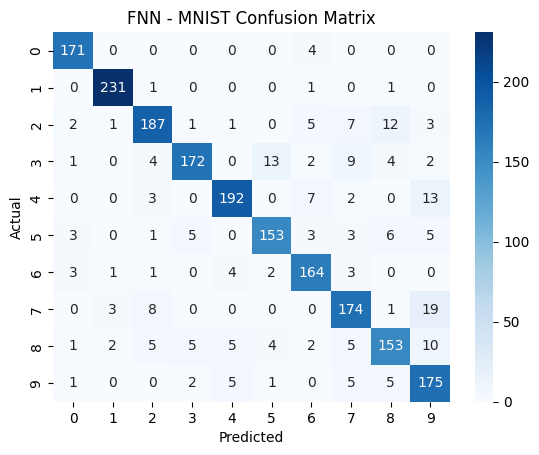

[FNN 7] Plotting accuracy and loss...


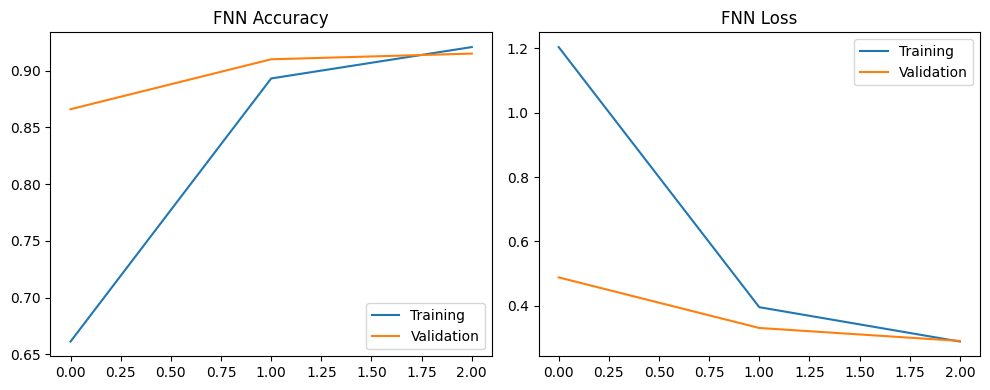

FNN COMPLETED!

[CNN 1] Loading Fashion-MNIST dataset...
[CNN 2] Preprocessing images...
[CNN 3] Building model...
[CNN 4] Training started...
Epoch 1/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.6743 - loss: 1.0800 - val_accuracy: 0.7600 - val_loss: 0.6694
Epoch 2/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.8090 - loss: 0.5538 - val_accuracy: 0.8170 - val_loss: 0.5253
Epoch 3/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.8343 - loss: 0.4703 - val_accuracy: 0.8310 - val_loss: 0.4708
[CNN 5] Evaluating model...
CNN Test Accuracy: 0.8475
              precision    recall  f1-score   support

     T-shirt       0.87      0.83      0.85       200
     Trouser       1.00      0.94      0.97       203
    Pullover       0.90      0.60      0.72       214
       Dress       0.76      0.90      0.82       190
        Coat       0.69      0.83      0.76       219
      Sandal       0.92      0.93      0.93       195
       Shirt       0.63      0.68      0.66   

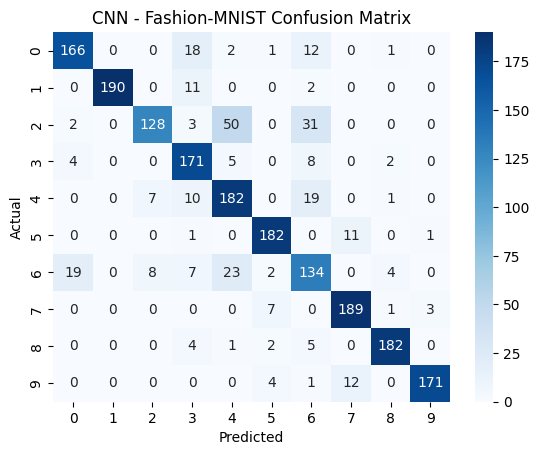

[CNN 7] Plotting accuracy and loss...


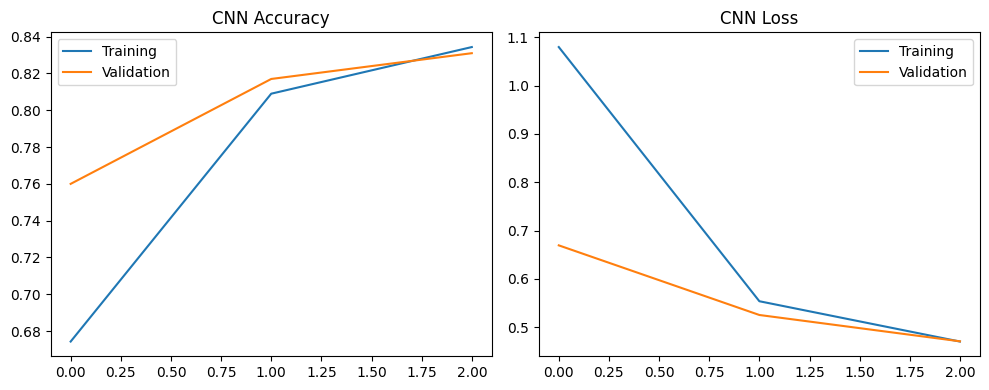

[CNN 8] Showing sample predictions...


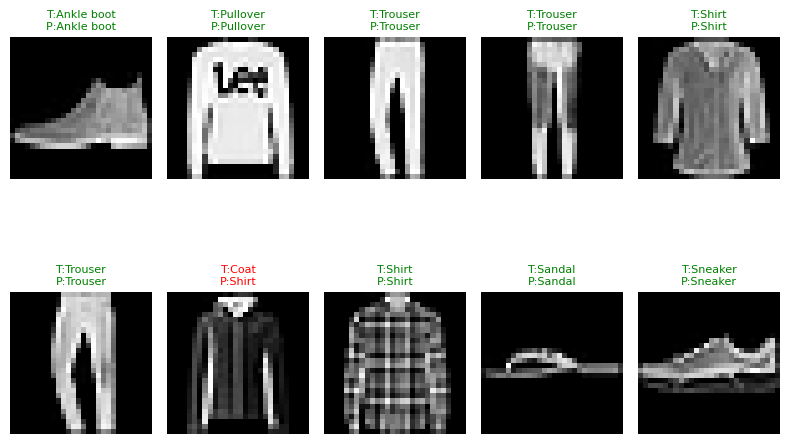


ALL PROCESSING COMPLETED!


In [3]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import Sequential, layers
from tensorflow.keras.datasets import mnist, fashion_mnist
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("PROGRAM STARTED!")

# =================================
# PART 1: FNN - DIGIT CLASSIFICATION
# =================================

print("\n[FNN 1] Loading MNIST dataset...")
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Use a smaller subset for faster execution
x_train, y_train = x_train[:10000], y_train[:10000]
x_test, y_test = x_test[:2000], y_test[:2000]

print("[FNN 2] Preprocessing data...")
x_train = x_train.reshape(-1, 784).astype("float32") / 255
x_test = x_test.reshape(-1, 784).astype("float32") / 255

print("[FNN 3] Building model...")
fnn = Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

fnn.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

print("[FNN 4] Training started...")
history_fnn = fnn.fit(
    x_train, y_train,
    epochs=3, batch_size=128,
    validation_split=0.1, verbose=1
)

print("[FNN 5] Evaluating model...")
loss, acc = fnn.evaluate(x_test, y_test, verbose=0)
print("FNN Test Accuracy:", round(acc, 4))

pred_fnn = np.argmax(fnn.predict(x_test, verbose=0), axis=1)
print(classification_report(y_test, pred_fnn, zero_division=0))

print("[FNN 6] Plotting confusion matrix...")
sns.heatmap(confusion_matrix(y_test, pred_fnn),
            cmap="Blues", annot=True, fmt="d")
plt.title("FNN - MNIST Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("[FNN 7] Plotting accuracy and loss...")
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_fnn.history["accuracy"], label="Training")
plt.plot(history_fnn.history["val_accuracy"], label="Validation")
plt.title("FNN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_fnn.history["loss"], label="Training")
plt.plot(history_fnn.history["val_loss"], label="Validation")
plt.title("FNN Loss")
plt.legend()

plt.tight_layout()
plt.show()

print("FNN COMPLETED!")


# =====================================
# PART 2: CNN - CLOTHING CLASSIFICATION
# =====================================

print("\n[CNN 1] Loading Fashion-MNIST dataset...")
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Use a smaller subset
x_train, y_train = x_train[:10000], y_train[:10000]
x_test, y_test = x_test[:2000], y_test[:2000]

print("[CNN 2] Preprocessing images...")
x_train = x_train[..., np.newaxis].astype("float32") / 255
x_test = x_test[..., np.newaxis].astype("float32") / 255

print("[CNN 3] Building model...")
cnn = Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

cnn.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

print("[CNN 4] Training started...")
history_cnn = cnn.fit(
    x_train, y_train,
    epochs=3, batch_size=128,
    validation_split=0.1, verbose=1
)

print("[CNN 5] Evaluating model...")
loss, acc = cnn.evaluate(x_test, y_test, verbose=0)
print("CNN Test Accuracy:", round(acc, 4))

pred_cnn = np.argmax(cnn.predict(x_test, verbose=0), axis=1)

class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(classification_report(
    y_test, pred_cnn, target_names=class_names, zero_division=0
))

print("[CNN 6] Plotting confusion matrix...")
sns.heatmap(confusion_matrix(y_test, pred_cnn),
            cmap="Blues", annot=True, fmt="d")
plt.title("CNN - Fashion-MNIST Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("[CNN 7] Plotting accuracy and loss...")
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Training")
plt.plot(history_cnn.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Training")
plt.plot(history_cnn.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.legend()

plt.tight_layout()
plt.show()

print("[CNN 8] Showing sample predictions...")
plt.figure(figsize=(8, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(
        f"T:{class_names[y_test[i]]}\nP:{class_names[pred_cnn[i]]}",
        fontsize=8,
        color="green" if y_test[i] == pred_cnn[i] else "red"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

print("\nALL PROCESSING COMPLETED!")
